# Tutorial 1: Higher-order interactions in healthy ageing

## Objective
In this tutorial we study how **redundant** and **synergistic** interactions among brain modules change with age, using the O-information [1].

We will:
1. Compute the O-information of every triplet of brain modules, in one of two ways (choose one):
   - **Option A**: the HOI toolbox [2];
   - **Option B**: loading precomputed results.
2. Compare **younger** vs **older** participants: first for every triplet, and then **projecting down** the triplets to modules (nodes).
3. Look at age as a **continuous** variable across the lifespan.
4. Discuss the advantages and challenges of projecting down.

<img src="lifespan.png" width="400">

## Definition

The O-information is a multivariate measure of information capable of disentangling whether a set of variables $X^n = (X_1, \dots, X_n)$ is dominated by redundancy or synergy. It is defined as the difference between the Total Correlation (TC) and the Dual Total Correlation (DTC) [1]:

$$
\Omega(X^{n}) = TC(X^{n}) - DTC(X^{n}) = (n - 2)H(X^{n}) + \sum_{j=1}^{n} \left[ H(X_{j}) - H(X_{-j}^{n}) \right]
$$

- $\Omega > 0$: the interaction is dominated by **redundancy** (information shared by the variables, copies of the same information).
- $\Omega < 0$: the interaction is dominated by **synergy** (information that only appears when looking at the variables jointly).

Here entropies are estimated with the **Gaussian copula** approach: each time series is rank-transformed into a standard Gaussian, so all entropies can be computed from the covariance matrix.

### Dataset
- 161 participants, aged 10 to 80 years.
- fMRI time series of 20 brain modules per participant (`timeseries/ts_m20_pXXX.txt`).
- Age vector (`ages_up.mat`).

The data and the original MATLAB code are available at www.github.com/brincolab/High-Order-interactions [3].

#### References
[1] Rosas FE, Mediano PAM, Gastpar M, Jensen HJ. Quantifying high-order interdependencies via multivariate extensions of the mutual information. Phys Rev E. 2019;100(3):032305. doi: 10.1103/PhysRevE.100.032305

[2] HOI toolbox: https://brainets.github.io/hoi/

[3] Gatica M, Cofré R, Mediano PAM, Rosas FE, Orio P, Diez I, Swinnen SP, Cortes JM. High-order interdependencies in the aging brain. Brain Connectivity. 2021. doi: 10.1089/brain.2020.0982

## 0. Setup

Keep this notebook in the same folder as the data files (`ages_up.mat`, `Oinfo_triplets_m20.npy` and the `timeseries/` folder).

Choose how you want to obtain the O-information values:

| `MODE` | What it does | Requirements |
|---|---|---|
| `"hoi"` | Computes the O-information with the HOI toolbox | `pip install -U hoi` ([installation guide](https://brainets.github.io/hoi/install.html#installation)) |
| `"load"` | Loads precomputed values from `OINFO_FILE` | the `.npy` file |

In [60]:
import os
from itertools import combinations
from math import ceil

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.io import loadmat
from scipy.stats import mannwhitneyu, spearmanr

In [61]:
MODE = "load"          # "hoi" or "load"

DATA_DIR   = "."                                 # folder with the data (same as the notebook)

TS_PATTERN = "timeseries/ts_m20_p{:03d}.txt"     # one file per participant
AGES_FILE  = "ages_up.mat"
OINFO_FILE = "Oinfo_triplets_m20.npy"            # precomputed (participants x triplets)

N_SUBJ  = 161
N_NODES = 20
ORDER   = 3            # 3 = triplets

nplets = np.array(list(combinations(range(N_NODES), ORDER)))   # (1140, 3)
print("Number of triplets:", len(nplets))

Number of triplets: 1140


## 1. Loading the data

### 1.1 Age of the participants

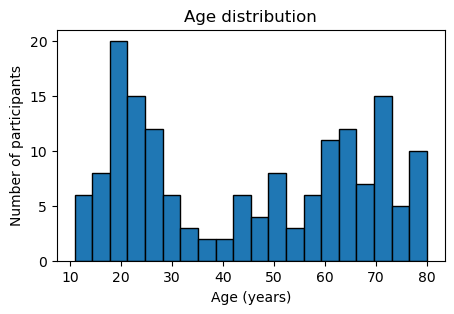

In [62]:
age = loadmat(os.path.join(DATA_DIR, AGES_FILE))["ages_up"].squeeze()   # (161,)

plt.figure(figsize=(5, 3))
plt.hist(age, bins=20, edgecolor="black")
plt.xlabel("Age (years)")
plt.ylabel("Number of participants")
plt.title("Age distribution")
plt.show()

### 1.2 Time series

Each file contains the time series of the 20 modules. We store them as arrays of shape `(T, N)` = (time points, modules), which is the convention used by HOI and by our functions below.

Note that the number of time points is not the same for everyone (between 159 and 200). You could also truncate all participants to the same length, as recommended in [3].

Participant 1: (200, 20) (time points, modules)
Time points per participant: [159, 160, 199, 200]


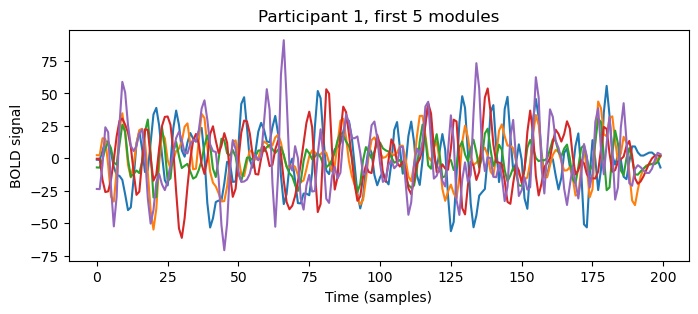

In [63]:
def load_timeseries(subj):
    X = np.loadtxt(os.path.join(DATA_DIR, TS_PATTERN.format(subj)))
    if X.shape[0] == N_NODES:          # files are stored as (modules, time)
        X = X.T
    return X                            # (T, N)


timeseries = [load_timeseries(s) for s in range(1, N_SUBJ + 1)]
print("Participant 1:", timeseries[0].shape, "(time points, modules)")
print("Time points per participant:", sorted(set(X.shape[0] for X in timeseries)))

plt.figure(figsize=(8, 3))
plt.plot(timeseries[0][:, :5])
plt.xlabel("Time (samples)")
plt.ylabel("BOLD signal")
plt.title("Participant 1, first 5 modules")
plt.show()

## 2. Computing the O-information of every triplet

Both options produce the same object:

`Oinfo` : array of shape `(participants, triplets)`, where `Oinfo[s, k]` is the O-information of triplet `nplets[k]` in participant `s`.

Only the option that matches your `MODE` runs; the others are skipped.

<div style="background-color:#DCEFF7; color:#14213D; padding:12px 16px; border-radius:8px; border-left:6px solid #2B5FA8"><b>OPTION A · HOI toolbox</b><br>Runs when <code>MODE = "hoi"</code>. Requires HOI to be installed.</div>

[HOI](https://brainets.github.io/hoi/) (Higher-Order Interactions) is a Python package to quantify statistical dependencies between two or more variables with information-theoretic metrics.

**What is inside**
- **Metrics** of interactions within a set of variables: total correlation (`TC`), dual total correlation (`DTC`), O-information (`Oinfo`) and S-information (`Sinfo`). It also includes more general decompositions, such as the integrated information decomposition (ΦID) atoms.
- **Entropy estimators**, chosen with `method`: for example the Gaussian copula (`"gc"`, the default and the one we use here), `"gauss"` or `"kernel"`.
- **Utilities**: `fit(minsize, maxsize)` computes all multiplets from size `minsize` to size `maxsize` in one call, and `hoi.utils.get_nbest_mult` gives a table of the strongest multiplets.

Every metric follows the same pattern:

```python
model = hoi.metrics.Oinfo(data)            # data: (n_samples, n_features)
values = model.fit(minsize=3, maxsize=3, method="gc")
```

HOI uses the same Gaussian copula estimator as the original MATLAB code [3]. Documentation: https://brainets.github.io/hoi/

**Installation.** Follow the [installation guide](https://brainets.github.io/hoi/install.html#installation) (Python, Jax and the other dependencies). If HOI is not installed, use `MODE = "load"`: the results are the same.

In [64]:
if MODE == "hoi":
    import hoi

    Oinfo = np.zeros((N_SUBJ, len(nplets)))
    for s_idx, X in enumerate(timeseries):
        model = hoi.metrics.Oinfo(X)                   # input: (n_samples, n_features)
        res = np.asarray(model.fit(minsize=ORDER, maxsize=ORDER, method="gc")).squeeze()

        Oinfo[s_idx] = res
        if (s_idx + 1) % 20 == 0:
            print(f"{s_idx + 1}/{N_SUBJ} participants done")

<div style="background-color:#DCEFF7; color:#14213D; padding:12px 16px; border-radius:8px; border-left:6px solid #2B5FA8"><b>OPTION B · Load precomputed results</b><br>Runs when <code>MODE = "load"</code>. The fastest option.</div>

In [65]:
if MODE == "load":
    Oinfo = np.load(os.path.join(DATA_DIR, OINFO_FILE))

print("Oinfo shape:", Oinfo.shape, "(participants, triplets)")

Oinfo shape: (161, 1140) (participants, triplets)


<div style="background-color:#DFF3E4; color:#14213D; padding:12px 16px; border-radius:8px; border-left:6px solid #2E8B57"><b>CHECKPOINT 1</b><br>You should see <code>Oinfo shape: (161, 1140)</code>: 161 participants, 1140 triplets each.</div>

To create the file used in Option B (run once, after Option A):

In [66]:
# np.save(os.path.join(DATA_DIR, OINFO_FILE), Oinfo)

## 3. Younger vs older participants

We compare the youngest and oldest participants. Effect sizes are measured with **Cohen's d** (older minus younger): positive d means the value is larger in older participants. As a rough guide, |d| = 0.2 is small, 0.5 medium and 0.8 large. Significance is tested with the **Mann-Whitney U test** (non-parametric), with **Bonferroni correction** for the number of tests.

We start with the **triplets**, and then **project down** the triplets to the 20 modules.

In [67]:
young = age <= 20
old   = age >= 60
print("Younger (<= 20 y):", young.sum(), "participants")
print("Older   (>= 60 y):", old.sum(), "participants")


def cohens_d(x, y):
    """Cohen's d of x - y with pooled standard deviation."""
    nx, ny = len(x), len(y)
    pooled = np.sqrt(((nx - 1) * np.var(x, ddof=1) + (ny - 1) * np.var(y, ddof=1)) / (nx + ny - 2))
    return (np.mean(x) - np.mean(y)) / pooled


def bonferroni(p):
    """Bonferroni-corrected p-values: p times the number of tests (at most 1)."""
    p = np.asarray(p)
    return np.minimum(p * len(p), 1)


def plot_effects(values, p_bonf, ax, color="gray", alpha=0.05, s=25):
    """Dot plot of one effect size per element; significant elements (p_bonf < alpha) get a black circle."""
    x = np.arange(1, len(values) + 1)
    ax.scatter(x, values, s=s, c=color, zorder=2)
    sig = p_bonf < alpha
    ax.scatter(x[sig], values[sig], s=s * 3, facecolors="none", edgecolors="k", lw=1.2, zorder=3,
               label=f"p < {alpha} (Bonferroni)")
    ax.axhline(0, color="k", lw=0.8)
    ax.margins(y=0.15)
    return ax

Younger (<= 20 y): 28 participants
Older   (>= 60 y): 59 participants


### 3.1 Triplet level: which interactions change the most?

We compute Cohen's d **for every triplet**, plus a Mann-Whitney U test with Bonferroni correction across the 1140 triplets. Each dot is a triplet: blue dots have a higher O-information in older participants (d > 0), red dots a lower one (d < 0). Significant triplets are marked with a black circle.

Significant triplets (Bonferroni): 9 of 1140
  higher O-information in older participants (d > 0): 6
  lower O-information in older participants (d < 0):  3


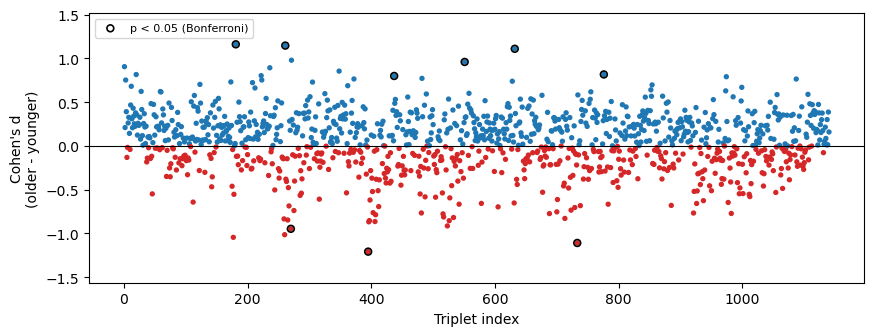

In [68]:
d_trip = np.array([cohens_d(Oinfo[old, k], Oinfo[young, k]) for k in range(len(nplets))])
p_trip = mannwhitneyu(Oinfo[old], Oinfo[young], axis=0).pvalue
pb_trip = bonferroni(p_trip)
sig_trip = pb_trip < 0.05

mean_young = Oinfo[young].mean(axis=0)
mean_old   = Oinfo[old].mean(axis=0)

print("Significant triplets (Bonferroni):", sig_trip.sum(), "of", len(nplets))
print("  higher O-information in older participants (d > 0):", np.sum(sig_trip & (d_trip > 0)))
print("  lower O-information in older participants (d < 0): ", np.sum(sig_trip & (d_trip < 0)))

fig, ax = plt.subplots(figsize=(10, 3.5))
plot_effects(d_trip, pb_trip, ax, color=np.where(d_trip > 0, "tab:blue", "tab:red"), s=8)
ax.set_xlabel("Triplet index")
ax.set_ylabel("Cohen's d\n(older - younger)")
ax.legend(loc="upper left", fontsize=8)
plt.show()

<div style="background-color:#DFF3E4; color:#14213D; padding:12px 16px; border-radius:8px; border-left:6px solid #2E8B57"><b>CHECKPOINT 2</b><br>You should find <b>9</b> significant triplets (Bonferroni-corrected p &lt; 0.05).</div>

The significant triplets, sorted by effect size:

In [69]:
table = pd.DataFrame({
    "triplet (modules)": [tuple((t + 1).tolist()) for t in nplets],
    "mean_young": mean_young,
    "mean_old": mean_old,
    "d": d_trip,
    "p (Bonferroni)": pb_trip,
})
display(table[sig_trip].sort_values("d").style.format(
    {"mean_young": "{:.3f}", "mean_old": "{:.3f}", "d": "{:.2f}", "p (Bonferroni)": "{:.1e}"}))

,triplet (modules),mean_young,mean_old,d,p (Bonferroni)
394,"(3, 9, 10)",0.095,0.005,-1.21,2.0e-04
732,"(6, 11, 13)",0.011,-0.035,-1.11,1.4e-03
269,"(2, 10, 11)",0.050,-0.018,-0.95,3.5e-02
436,"(3, 13, 18)",0.002,0.063,0.80,3.7e-02
775,"(6, 19, 20)",0.004,0.079,0.82,9.5e-03
550,"(4, 12, 19)",-0.018,0.000,0.96,3.1e-02
631,"(5, 10, 12)",-0.073,-0.003,1.11,5.7e-03
260,"(2, 9, 12)",-0.111,-0.036,1.15,3.8e-03
180,"(2, 3, 13)",0.012,0.132,1.16,2.1e-03


**Tip.** A triplet can also be drawn as a *hyperedge*, a shape that joins three nodes at once. The [xgi](https://xgi.readthedocs.io) package draws hypergraphs, and it is the tool used in the HOI documentation examples.

### 3.2 Projecting down: from triplets to modules

We now go from 1140 triplets to 20 modules (nodes), exactly as in `high_order.m` [3]. For each module we take the 171 triplets that contain it and compute:
- **Redundancy**: mean of the positive O-information values;
- **Synergy**: mean of the absolute value of the negative O-information values (0 if the module has no synergistic triplet).

In [70]:
def nodal_red_syn(Oinfo, nplets, n_nodes):
    """Redundancy and synergy per module, as in high_order.m [3].
    Returns two arrays of shape (participants, modules)."""
    n_subj = Oinfo.shape[0]
    Red = np.zeros((n_subj, n_nodes))
    Syn = np.zeros((n_subj, n_nodes))
    for s in range(n_subj):
        for node in range(n_nodes):
            o = Oinfo[s, np.any(nplets == node, axis=1)]   # triplets containing this module
            Red[s, node] = o[o > 0].mean() if np.any(o > 0) else 0
            Syn[s, node] = np.abs(o[o < 0]).mean() if np.any(o < 0) else 0
    return Red, Syn


Red, Syn = nodal_red_syn(Oinfo, nplets, N_NODES)
print("Red, Syn shapes:", Red.shape, Syn.shape)

Red, Syn shapes: (161, 20) (161, 20)


For each module we compare older vs younger participants with Cohen's d (y axis) and a Mann-Whitney U test, Bonferroni-corrected across the 20 modules. Modules with a significant difference are marked with a black circle.

Redundancy: significant modules (Bonferroni): [ 1 13 15 19 20]
Synergy:    significant modules (Bonferroni): []


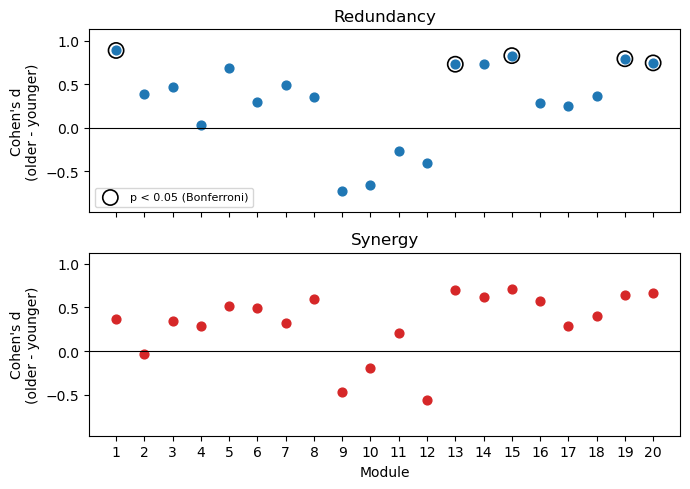

In [71]:
d_red = np.array([cohens_d(Red[old, n], Red[young, n]) for n in range(N_NODES)])
d_syn = np.array([cohens_d(Syn[old, n], Syn[young, n]) for n in range(N_NODES)])
pb_red = bonferroni(mannwhitneyu(Red[old], Red[young], axis=0).pvalue)
pb_syn = bonferroni(mannwhitneyu(Syn[old], Syn[young], axis=0).pvalue)

print("Redundancy: significant modules (Bonferroni):", np.where(pb_red < 0.05)[0] + 1)
print("Synergy:    significant modules (Bonferroni):", np.where(pb_syn < 0.05)[0] + 1)

x = np.arange(1, N_NODES + 1)
fig, axes = plt.subplots(2, 1, figsize=(7, 5), sharex=True, sharey=True)
for ax, d, pb, lab, col in zip(axes, [d_red, d_syn], [pb_red, pb_syn], ["Redundancy", "Synergy"], ["tab:blue", "tab:red"]):
    plot_effects(d, pb, ax, color=col, s=40)
    ax.set_ylabel("Cohen's d\n(older - younger)")
    ax.set_title(lab)
axes[0].legend(loc="lower left", fontsize=8)
axes[1].set_xlabel("Module")
axes[1].set_xticks(x)
plt.tight_layout()
plt.show()

<img src="SFMs.png" width="400">

*Brain atlas and image: Diez I, Bonifazi P, Escudero I, et al. A novel brain partition highlights the modular skeleton shared by structure and function. Sci Rep 5, 10532 (2015). https://doi.org/10.1038/srep10532*

## 4. Age as a continuous variable

Splitting into groups discards the participants in the middle of the lifespan. Here we use all 161 participants and go directly to the modules: which modules change the most across the lifespan?

### 4.1 Modules across the lifespan

For each module we compute the Spearman correlation between age and its redundancy and synergy, with Bonferroni correction across the 20 modules. Below, one panel for each module that changes significantly with age.

Redundancy: significant modules (Bonferroni): [ 1  5  9 13 15 19 20]


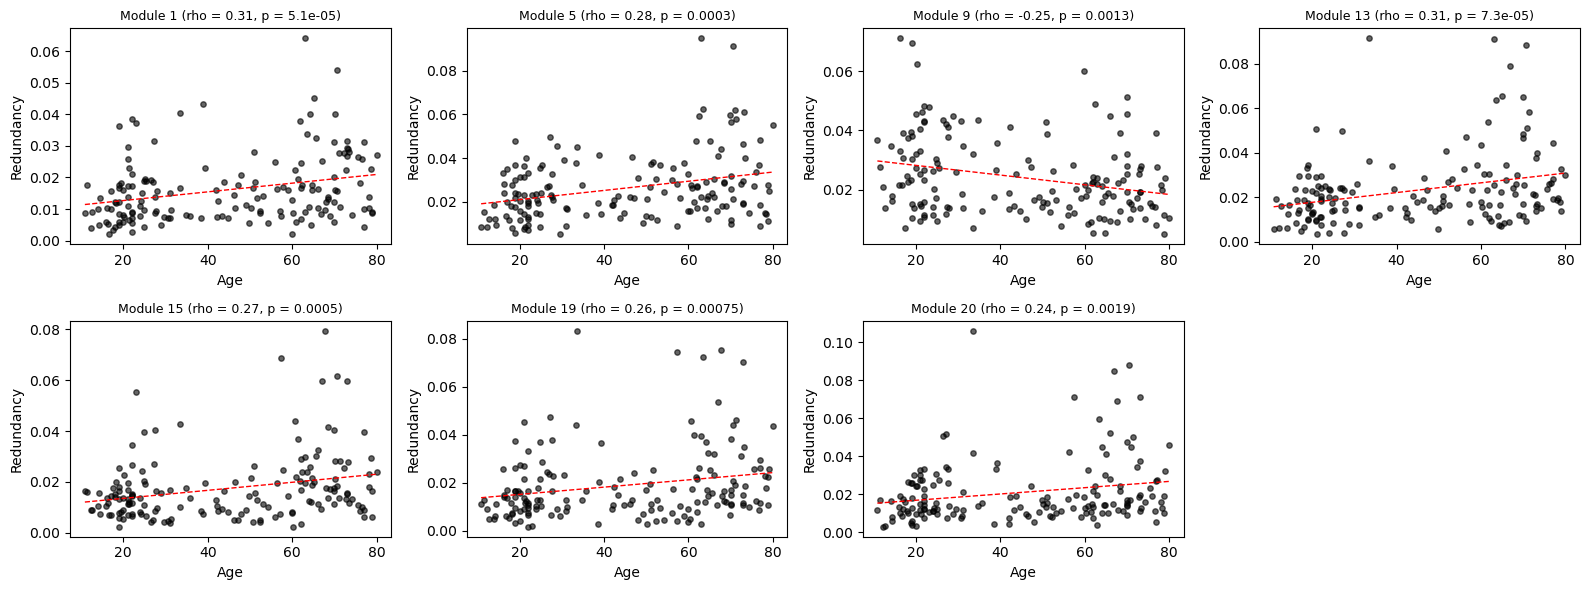

Synergy: significant modules (Bonferroni): [13 15]


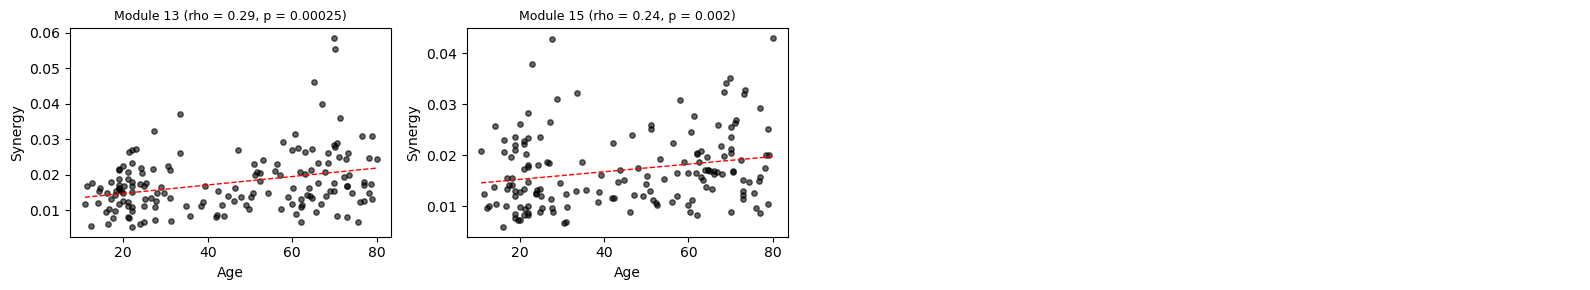

In [72]:
alpha = 0.05 / N_NODES   # Bonferroni

def plot_age_vs_metric(age, M, ylabel):
    r = np.zeros(M.shape[1])
    p = np.zeros(M.shape[1])
    for n in range(M.shape[1]):
        r[n], p[n] = spearmanr(age, M[:, n])
    sig = np.where(p <= alpha)[0]
    print(f"{ylabel}: significant modules (Bonferroni):", sig + 1)
    if len(sig) == 0:
        return

    ncols = 4
    nrows = ceil(len(sig) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), squeeze=False)
    for ax, n in zip(axes.ravel(), sig):
        ax.scatter(age, M[:, n], c="k", s=15, alpha=0.6)
        z = np.polyfit(age, M[:, n], 1)
        ax.plot(np.sort(age), np.polyval(z, np.sort(age)), "r--", lw=1)
        ax.set_title(f"Module {n + 1} (rho = {r[n]:.2f}, p = {p[n]:.2g})", fontsize=9)
        ax.set_xlabel("Age")
        ax.set_ylabel(ylabel)
    for ax in axes.ravel()[len(sig):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


plot_age_vs_metric(age, Red, "Redundancy")
plot_age_vs_metric(age, Syn, "Synergy")

<div style="background-color:#DFF3E4; color:#14213D; padding:12px 16px; border-radius:8px; border-left:6px solid #2E8B57"><b>CHECKPOINT 3</b><br>You should find <b>7</b> modules whose redundancy changes with age, and <b>2</b> whose synergy changes with age.</div>

### 4.2 Are the triplets of section 3.1 coherent across the lifespan?

For the triplets that differ between younger and older participants (section 3.1), we check whether their O-information also changes with age when we use all participants, and in the same direction.

In [73]:
sig_idx = np.where(sig_trip)[0]
rho_sig = np.array([spearmanr(age, Oinfo[:, k])[0] for k in sig_idx])
p_sig = np.array([spearmanr(age, Oinfo[:, k])[1] for k in sig_idx])

coherence = pd.DataFrame({
    "triplet (modules)": [tuple((nplets[k] + 1).tolist()) for k in sig_idx],
    "d (older - younger)": d_trip[sig_idx],
    "rho (age)": rho_sig,
    "p (Bonferroni)": bonferroni(p_sig),
    "same direction": np.sign(d_trip[sig_idx]) == np.sign(rho_sig),
})
display(coherence.sort_values("d (older - younger)").style.format(
    {"d (older - younger)": "{:.2f}", "rho (age)": "{:.2f}", "p (Bonferroni)": "{:.1e}"}))

,triplet (modules),d (older - younger),rho (age),p (Bonferroni),same direction
3,"(3, 9, 10)",-1.21,-0.47,4.1e-09,True
7,"(6, 11, 13)",-1.11,-0.37,1.0e-05,True
2,"(2, 10, 11)",-0.95,-0.38,6.8e-06,True
4,"(3, 13, 18)",0.80,0.31,4.9e-04,True
8,"(6, 19, 20)",0.82,0.38,7.2e-06,True
5,"(4, 12, 19)",0.96,0.33,2.0e-04,True
6,"(5, 10, 12)",1.11,0.43,1.6e-07,True
1,"(2, 9, 12)",1.15,0.41,7.8e-07,True
0,"(2, 3, 13)",1.16,0.41,6.4e-07,True


**Summary.** On average, at the level of modules, redundancy increases with age. Locally, at the level of triplets, there are more effects, and they go in both directions: some triplets shift toward redundancy and others toward synergy.

**Note.** For simplicity, this tutorial uses Spearman correlations, which capture **monotonic** age effects (values that only go up, or only go down, with age). Non-monotonic trajectories, such as values that increase and then decrease across the lifespan, would be missed; they can be modelled explicitly, for example by adding a quadratic term in age.

## 5. Discussion

<div style="background-color:#DFF3E4; color:#14213D; padding:12px 16px; border-radius:8px; border-left:6px solid #2E8B57"><b>DISCUSSION</b><br>Take a few minutes in groups to discuss these questions.</div>

1. **Projecting down.** We summarized 1140 triplets into 20 modules. What are the advantages and the challenges of doing this, and why?
2. **Your own research.** Think of a scenario in your work where projecting down would be the right choice, and one where it would hide what you care about.
3. **Discrete vs continuous.** Two age groups or age as a continuous variable: what are the advantages and limitations of each?

## 6. Try it with your own data

Everything in this tutorial only needs, for each participant, a matrix of shape `(T, N)` (time points x variables). To use your own data:

1. Load one `(T, N)` array per participant into the list `timeseries`.
2. Set `N_SUBJ` and `N_NODES`, and recompute `nplets`.
3. Compute `Oinfo` with HOI (Option A).
4. Replace `age` by your own variable of interest (or define your own groups instead of `young` and `old`) and run sections 3 and 4.

In [74]:
# Template: replace with your own files and variable of interest
# timeseries = [np.loadtxt(f) for f in my_files]      # list of (T, N) arrays
# N_SUBJ, N_NODES = len(timeseries), timeseries[0].shape[1]
# nplets = np.array(list(combinations(range(N_NODES), ORDER)))
# Oinfo = np.array([np.asarray(hoi.metrics.Oinfo(X).fit(minsize=ORDER, maxsize=ORDER, method="gc")).squeeze()
#                   for X in timeseries])
# age = my_variable                                   # (N_SUBJ,)